# Multi Coin Cryptocurrency Forecasting with LSTM

One LSTM model, trained on several coins at once, predicts each coin's price **7 days ahead**. Each coin
has its own ID, so the model can learn general patterns from all coins together while still giving each
coin its own prediction.

**How it works, in short**
- **What the model predicts:** the price change (as a log-return) over the next 7 days, not the raw price.
  This is easier to learn and is turned back into a price at the end.
- **Inputs:** price returns, a few common indicators (moving averages, RSI, MACD, Bollinger Bands) written
  as ratios to the current price instead of raw price, plus Bitcoin's return as a market signal.
- **Model:** a shared Conv1D + LSTM + LSTM core, with one small output layer per coin.
- **Data split:** 70% train / 15% validation / 15% test, in time order (no shuffling across time), done
  separately for each coin.
- **Checking the result:** every score is compared to a simple baseline ("the price does not change"), so
  it is clear whether the model is actually better than doing nothing.

*This is a research project, not financial advice.*

## 1. Setup

This runs on the normal Google Colab setup, no extra installs needed. Using a GPU
(Runtime → Change runtime type → T4 GPU) makes training faster.

In [ ]:
# Cell 1 — Setup
import time
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras import Input, Model, layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

print(f"TensorFlow {tf.__version__} | GPU: {bool(tf.config.list_physical_devices('GPU'))}")

TensorFlow 2.21.0 | GPU: True


## 2. Settings

All the numbers you might want to change live here in one place, instead of scattered through the notebook.

In [ ]:
# Cell 2 — Settings
@dataclass
class Config:
    assets: list = field(default_factory=lambda: [
        "BTC", "ETH", "LTC", "DOGE", "XRP", "ADA", "SOL", "DOT",
    ])
    min_rows: int = 1000
    window_size: int = 60
    forecast_horizon: int = 7
    train_ratio: float = 0.70
    val_ratio: float = 0.15
    test_ratio: float = 0.15
    batch_size: int = 64
    epochs: int = 80
    learning_rate: float = 5e-4
    embedding_dim: int = 16
    dropout: float = 0.25
    l2_penalty: float = 1e-4
    early_stop_patience: int = 10
    reduce_lr_patience: int = 4
    seed: int = 42
    results_dir: Path = Path("results")

    @property
    def figures_dir(self) -> Path:
        return self.results_dir / "figures"


cfg = Config()
cfg.figures_dir.mkdir(parents=True, exist_ok=True)
assert abs(cfg.train_ratio + cfg.val_ratio + cfg.test_ratio - 1.0) < 1e-9

np.random.seed(cfg.seed)
tf.keras.utils.set_random_seed(cfg.seed)

print("Assets:", cfg.assets)
print("Window:", cfg.window_size, "| Horizon:", cfg.forecast_horizon, "| Embedding dim:", cfg.embedding_dim)

Assets: ['BTC', 'ETH', 'LTC', 'DOGE', 'XRP', 'ADA', 'SOL', 'DOT']
Window: 60 | Horizon: 7 | Embedding dim: 16


## 3. Getting the Data

Daily price data comes from Binance's free public API (no account or key needed) and is downloaded fresh
each time the notebook runs. Each coin keeps only its longest stretch of days with no gaps, since a missing
day would break the sliding windows used later.

In [ ]:
# Cell 3 — Data Acquisition
BINANCE_KLINES_URL = "https://data-api.binance.vision/api/v3/klines"
KLINES_LIMIT = 1000
OHLCV = ["open", "high", "low", "close", "volume"]


def longest_contiguous(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.sort_values("date").drop_duplicates("date").reset_index(drop=True)
    gaps = frame["date"].diff().dt.days.fillna(1)
    run_id = (gaps != 1).cumsum()
    return frame.loc[run_id == run_id.value_counts().idxmax()].reset_index(drop=True)


def download_daily_candles(symbol: str) -> pd.DataFrame:
    rows, start_ms = [], 0
    while True:
        r = requests.get(BINANCE_KLINES_URL, timeout=30,
                         params={"symbol": symbol, "interval": "1d", "startTime": start_ms, "limit": KLINES_LIMIT})
        r.raise_for_status()
        batch = r.json()
        if not batch:
            break
        rows.extend(batch)
        start_ms = int(batch[-1][6]) + 1
        if len(batch) < KLINES_LIMIT:
            break
        time.sleep(0.1)
    if not rows:
        raise ValueError("No data returned")

    df = pd.DataFrame(rows).iloc[:, :6]
    df.columns = ["open_time"] + OHLCV
    df["date"] = pd.to_datetime(df["open_time"], unit="ms", utc=True).dt.tz_localize(None).dt.normalize()
    df[OHLCV] = df[OHLCV].astype(float)

    today = pd.Timestamp.now(tz="UTC").tz_localize(None).normalize()
    df = df[df["date"] < today]
    df = df[["date"] + OHLCV].dropna().sort_values("date").drop_duplicates("date", keep="last")
    df = df[(df[["open", "high", "low", "close"]] > 0).all(axis=1)]
    return longest_contiguous(df)


price_data = {}
for symbol in cfg.assets:
    try:
        df = download_daily_candles(f"{symbol}USDT")
        if len(df) >= cfg.min_rows:
            price_data[symbol] = df
            print(f"{symbol:>5} | rows={len(df):>5} | {df['date'].min().date()} -> {df['date'].max().date()}")
        else:
            print(f"{symbol:>5} | skipped (only {len(df)} rows)")
    except Exception as e:
        print(f"{symbol:>5} | FAILED: {str(e)[:100]}")

assert "BTC" in price_data, "BTC is required as the market-reference series"
btc_series = price_data["BTC"][["date", "close"]].rename(columns={"close": "btc_close"})
print(f"\nLoaded {len(price_data)} coins.")

  BTC | rows= 3346 | 2017-08-17 -> 2026-10-14
  ETH | rows= 3346 | 2017-08-17 -> 2026-10-14
  LTC | rows= 3228 | 2017-12-13 -> 2026-10-14
 DOGE | rows= 2659 | 2019-07-05 -> 2026-10-14
  XRP | rows= 3086 | 2018-05-04 -> 2026-10-14
  ADA | rows= 3103 | 2018-04-17 -> 2026-10-14
  SOL | rows= 2256 | 2020-08-11 -> 2026-10-14
  DOT | rows= 2249 | 2020-08-18 -> 2026-10-14

Loaded 8 coins.


## 4. Building the Features

Moving averages, MACD, and Bollinger Bands are normally in raw price units, which is a problem: a coin's
price today can be far outside the range it was in during training. To avoid that, these are written as
**ratios to the current close price** instead, so they stay in a similar, small range no matter how high
or low the price has gone. The raw `close` price is still kept as one feature, so later steps can work out
the exact price again.

In [ ]:
# Cell 4 — Feature Engineering
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy()
    c = d["close"]

    sma_5, sma_9, sma_17 = c.rolling(5).mean(), c.rolling(9).mean(), c.rolling(17).mean()
    ema_7 = c.ewm(span=7, adjust=False).mean()
    ema_30 = c.ewm(span=30, adjust=False).mean()
    ema_90 = c.ewm(span=90, adjust=False).mean()

    delta = c.diff()
    gain = delta.clip(lower=0).rolling(14).mean()
    loss = -delta.clip(upper=0).rolling(14).mean()
    d["rsi_14"] = 100 - 100 / (1 + gain / (loss + 1e-9))

    ema12, ema26 = c.ewm(span=12, adjust=False).mean(), c.ewm(span=26, adjust=False).mean()
    macd = ema12 - ema26
    macd_signal = macd.ewm(span=9, adjust=False).mean()

    bb_mid, bb_std = c.rolling(20).mean(), c.rolling(20).std()
    bb_upper, bb_lower = bb_mid + 2 * bb_std, bb_mid - 2 * bb_std

    d["open_ratio"] = d["open"] / c - 1
    d["high_ratio"] = d["high"] / c - 1
    d["low_ratio"] = d["low"] / c - 1
    d["sma_5_ratio"] = sma_5 / c - 1
    d["sma_9_ratio"] = sma_9 / c - 1
    d["sma_17_ratio"] = sma_17 / c - 1
    d["ema_7_ratio"] = ema_7 / c - 1
    d["ema_30_ratio"] = ema_30 / c - 1
    d["ema_90_ratio"] = ema_90 / c - 1
    d["bb_upper_ratio"] = bb_upper / c - 1
    d["bb_lower_ratio"] = bb_lower / c - 1
    d["macd_ratio"] = macd / c
    d["macd_signal_ratio"] = macd_signal / c

    d["log_volume"] = np.log1p(d["volume"])
    d["btc_ret_1"] = np.log(d["btc_close"] / d["btc_close"].shift(1))
    d["ret_1"] = c.pct_change(1)
    d["ret_7"] = c.pct_change(7)
    d["ret_30"] = c.pct_change(30)
    return d


RAW_LEVEL_COLS = ["close"]
RATIO_COLS = ["open_ratio", "high_ratio", "low_ratio", "sma_5_ratio", "sma_9_ratio", "sma_17_ratio",
             "ema_7_ratio", "ema_30_ratio", "ema_90_ratio", "bb_upper_ratio", "bb_lower_ratio",
             "macd_ratio", "macd_signal_ratio"]
OTHER_COLS = ["log_volume", "rsi_14", "btc_ret_1", "ret_1", "ret_7", "ret_30"]

feature_cols = RAW_LEVEL_COLS + RATIO_COLS + OTHER_COLS
n_features = len(feature_cols)
print("Number of features:", n_features)
print(feature_cols)

Number of features: 20
['close', 'open_ratio', 'high_ratio', 'low_ratio', 'sma_5_ratio', 'sma_9_ratio', 'sma_17_ratio', 'ema_7_ratio', 'ema_30_ratio', 'ema_90_ratio', 'bb_upper_ratio', 'bb_lower_ratio', 'macd_ratio', 'macd_signal_ratio', 'log_volume', 'rsi_14', 'btc_ret_1', 'ret_1', 'ret_7', 'ret_30']


## 5. Preparing the Dataset

Each coin's price history is cut into sliding windows, then all coins are combined into one dataset. The
feature scaler is fit **only on each coin's own training period**, so no information from the validation
or test period leaks into training.

In [ ]:
# Cell 5 — Dataset Construction
def prepare_coin(df_raw: pd.DataFrame, btc_ref: pd.DataFrame) -> dict:
    d = df_raw.copy().merge(btc_ref, on="date", how="left").sort_values("date").ffill().bfill()
    d = add_features(d).dropna().reset_index(drop=True)

    n_rows = len(d)
    train_end = int(n_rows * cfg.train_ratio)
    val_end = int(n_rows * (cfg.train_ratio + cfg.val_ratio))

    scaler = MinMaxScaler(feature_range=(0, 1))
    scaler.fit(d.loc[:train_end - 1, feature_cols])
    scaled = scaler.transform(d[feature_cols])

    log_close = np.log(d["close"].to_numpy())
    X_all, y_all, target_end_idx = [], [], []
    max_start = n_rows - cfg.window_size - cfg.forecast_horizon + 1

    for start in range(max_start):
        input_end = start + cfg.window_size
        target_start = input_end
        target_end = target_start + cfg.forecast_horizon - 1

        X_all.append(scaled[start:input_end])
        base_log = log_close[input_end - 1]
        y_all.append(log_close[target_start:target_end + 1] - base_log)
        target_end_idx.append(target_end)

    return {
        "df": d, "scaler": scaler,
        "X": np.asarray(X_all, dtype=np.float32), "y": np.asarray(y_all, dtype=np.float32),
        "target_end_idx": np.asarray(target_end_idx),
        "train_end": train_end, "val_end": val_end, "n_rows": n_rows,
    }


per_coin = {symbol: prepare_coin(df, btc_series) for symbol, df in price_data.items()}
crypto_to_id = {s: i for i, s in enumerate(per_coin.keys())}
n_cryptos = len(crypto_to_id)
print("n_cryptos =", n_cryptos)

X_combined, y_combined, cid_combined, split_combined = [], [], [], []
for symbol in per_coin:
    d = per_coin[symbol]
    cid = crypto_to_id[symbol]
    for i in range(len(d["X"])):
        X_combined.append(d["X"][i])
        y_combined.append(d["y"][i])
        cid_combined.append(cid)
        te = d["target_end_idx"][i]
        split_combined.append(0 if te < d["train_end"] else 1 if te < d["val_end"] else 2)

X_combined = np.asarray(X_combined, dtype=np.float32)
y_combined = np.asarray(y_combined, dtype=np.float32)
cid_combined = np.asarray(cid_combined, dtype=np.int32).reshape(-1, 1)
split_combined = np.asarray(split_combined, dtype=np.int32)

train_mask, val_mask, test_mask = split_combined == 0, split_combined == 1, split_combined == 2
X_train, y_train, cid_train = X_combined[train_mask], y_combined[train_mask], cid_combined[train_mask]
X_val, y_val, cid_val = X_combined[val_mask], y_combined[val_mask], cid_combined[val_mask]
X_test, y_test, cid_test = X_combined[test_mask], y_combined[test_mask], cid_combined[test_mask]

print(f"Total samples: {len(X_combined):,}  (train={train_mask.sum():,}, val={val_mask.sum():,}, test={test_mask.sum():,})")
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

n_cryptos = 8
Total samples: 22,505  (train=15,593, val=3,454, test=3,458)
Train: (15593, 60, 20) | Val: (3454, 60, 20) | Test: (3458, 60, 20)


## 6. Building the Model

Each coin gets an ID, which the model turns into a small embedding (a learned set of numbers for that
coin) and attaches to the price window. The shared layers process this for every coin; a small, separate
output layer at the end gives each coin its own final prediction.

In [ ]:
# Cell 6 — Model Architecture
def build_multi_coin_model(n_cryptos: int, window_size: int, n_features: int,
                           forecast_horizon: int, embedding_dim: int) -> Model:
    reg = regularizers.l2(cfg.l2_penalty)
    price_input = Input(shape=(window_size, n_features), name="price_input")
    crypto_input = Input(shape=(1,), name="crypto_id")

    emb = layers.Embedding(input_dim=n_cryptos, output_dim=embedding_dim, name="crypto_embedding")(crypto_input)
    emb = layers.Flatten()(emb)
    emb_repeated = layers.RepeatVector(window_size)(emb)
    x = layers.Concatenate()([price_input, emb_repeated])

    x = layers.Conv1D(32, 3, activation="relu", padding="same", kernel_regularizer=reg, name="shared_conv")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(cfg.dropout)(x)

    x = layers.LSTM(64, return_sequences=True, kernel_regularizer=reg, name="shared_lstm_1")(x)
    x = layers.Dropout(cfg.dropout)(x)
    x = layers.LSTM(32, return_sequences=False, kernel_regularizer=reg, name="shared_lstm_2")(x)
    x = layers.Dropout(cfg.dropout)(x)

    heads = []
    for i in range(n_cryptos):
        h = layers.Dense(32, activation="relu", kernel_regularizer=reg, name=f"head_{i}_dense")(x)
        h = layers.Dropout(cfg.dropout * 0.8)(h)
        h = layers.Dense(forecast_horizon, activation="linear", name=f"head_{i}_output")(h)
        heads.append(h)
    stacked = layers.Lambda(lambda outs: tf.stack(outs, axis=1), name="stack_heads")(heads)

    def select_crypto_head(inputs):
        stacked_heads, cid = inputs
        selected = tf.gather(stacked_heads, tf.cast(cid, tf.int32), batch_dims=1)
        return tf.squeeze(selected, axis=1)

    output = layers.Lambda(select_crypto_head, name="select_head")([stacked, crypto_input])
    return Model(inputs=[price_input, crypto_input], outputs=output, name="multi_coin_lstm")


model = build_multi_coin_model(n_cryptos, cfg.window_size, n_features, cfg.forecast_horizon, cfg.embedding_dim)
model.compile(optimizer=Adam(learning_rate=cfg.learning_rate), loss="mse", metrics=["mae"])
model.summary()

Model: "multi_coin_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ crypto_id           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ crypto_embedding    │ (None, 1, 16)     │        128 │ crypto_id[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 16)        │          0 │ crypto_embedding… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ price_input         │ (None, 60, 20)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 60, 16)    │          0 │ flatten[0][0]     │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 60, 36)    │          0 │ price_input[0][0… │
│ (Concatenate)       │                   │            │ repeat_vector[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_conv         │ (None, 60, 32)    │      3,488 │ concatenate[0][0] │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 60, 32)    │        128 │ shared_conv[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 60, 32)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_lstm_1       │ (None, 60, 64)    │     24,832 │ dropout[0][0]     │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 60, 64)    │          0 │ shared_lstm_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_lstm_2       │ (None, 32)        │     12,416 │ dropout_1[0][0]   │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32)        │          0 │ shared_lstm_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_0_dense        │ (None, 32)        │      1,056 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_1_dense        │ (None, 32)        │      1,056 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_2_dense        │ (None, 32)        │      1,056 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_3_dense        │ (None, 32)        │      1,056 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_4_dense        │ (None, 32)        │      1,056 │ dropout_2[0][0]   │
│ (Dense)             │                   │            │                 

 Total params: 51,288 (200.34 KB)

 Trainable params: 51,224 (200.09 KB)

 Non-trainable params: 64 (256.00 B)

## 7. Training

**A note on the numbers below:** `loss` and `mae` here are measured on the **return** the model predicts,
not on price. A `val_mae` of `0.06` means the model is off by about 6 percentage points on the 7-day
return — that's a fairly large miss, since most of these coins only move a few percent either way in 7
days. So a small-looking `val_loss` does **not** mean the price forecast is accurate. Section 10 shows the
real, price-based error for each coin — that's the number to trust.

In [ ]:
# Cell 7 — Training
callbacks = [
    EarlyStopping(monitor="val_loss", patience=cfg.early_stop_patience, min_delta=1e-5,
                 restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=cfg.reduce_lr_patience, min_lr=1e-6, verbose=1),
]

history = model.fit(
    [X_train, cid_train], y_train,
    validation_data=([X_val, cid_val], y_val),
    epochs=cfg.epochs, batch_size=cfg.batch_size, shuffle=True,
    callbacks=callbacks, verbose=1,
)

best_val_loss = min(history.history["val_loss"])
best_val_mae = history.history["val_mae"][int(np.argmin(history.history["val_loss"]))]
print(f"\nBest val_loss (MSE, log-return units): {best_val_loss:.6f}")
print(f"Best val_mae  (log-return units)      : {best_val_mae:.4f}  "
     f"(≈ {best_val_mae * 100:.1f} percentage points of {cfg.forecast_horizon}-day cumulative return)")
print(f"Total epochs: {len(history.history['loss'])}")
print("\nThis is NOT in the same units as the per-coin MAE/MAPE reported in Section 10 (price scale) -- "
     "see the note above Cell 7 before comparing the two.")

Epoch 1/80
244/244 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - loss: 0.0455 - mae: 0.0770 - val_loss: 0.0298 - val_mae: 0.0602 - learning_rate: 5.0000e-04
Epoch 2/80
244/244 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0272 - mae: 0.0689 - val_loss: 0.0183 - val_mae: 0.0598 - learning_rate: 5.0000e-04
Epoch 3/80
244/244 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0191 - mae: 0.0684 - val_loss: 0.0131 - val_mae: 0.0599 - learning_rate: 5.0000e-04
Epoch 4/80
244/244 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0155 - mae: 0.0683 - val_loss: 0.0109 - val_mae: 0.0604 - learning_rate: 5.0000e-04
Epoch 5/80
244/244 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0138 - mae: 0.0682 - val_loss: 0.0098 - val_mae: 0.0603 - learning_rate: 5.0000e-04
Epoch 6/80
244/244 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0130 - mae: 0.0683 - val_loss: 0.0093 - val_mae: 0.0604 - learning_rate: 5.0000e-04
Epoch 7/80
244/244 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0125 - mae: 0.0682 - val_loss: 0.0089 - val_mae: 0.060

## 8. Training Curves

A quick check that training went well: both lines should go down together. If the validation line turns
upward while the training line keeps falling, the model is starting to memorize instead of learn.

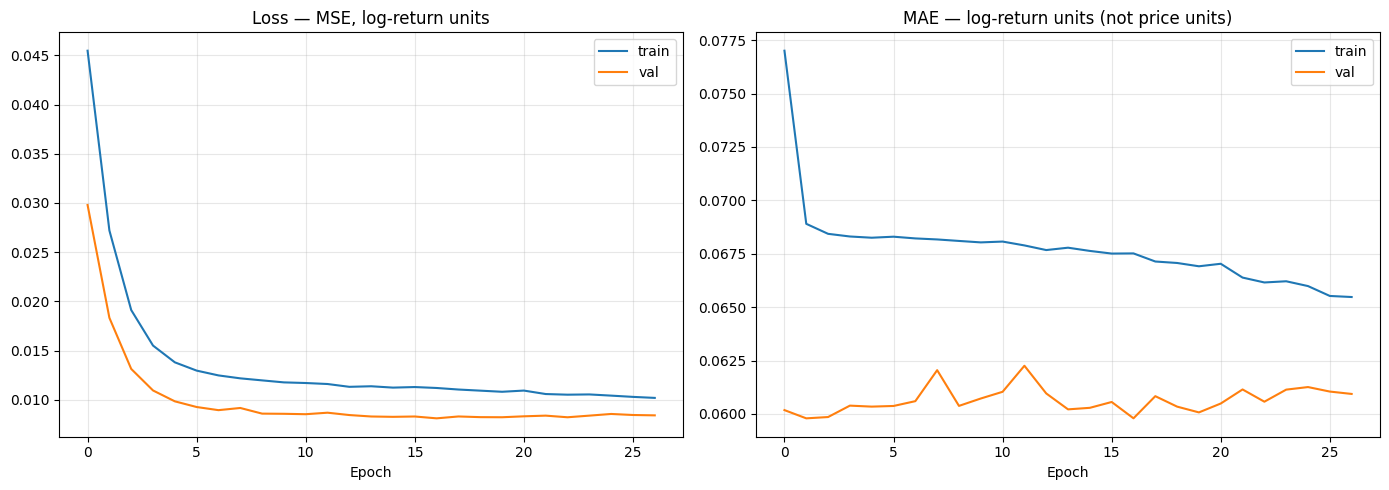

In [ ]:
# Cell 8 — Training Curves
def plot_training_curves(history, save_path: Path) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history.history["loss"], label="train")
    axes[0].plot(history.history["val_loss"], label="val")
    axes[0].set_title("Loss — MSE, log-return units")
    axes[0].set_xlabel("Epoch")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].plot(history.history["mae"], label="train")
    axes[1].plot(history.history["val_mae"], label="val")
    axes[1].set_title("MAE — log-return units (not price units)")
    axes[1].set_xlabel("Epoch")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    fig.tight_layout()
    fig.savefig(save_path, dpi=130)
    plt.show()


plot_training_curves(history, cfg.figures_dir / "training_curves.png")

## 9. Prediction Helpers

Small functions used everywhere below. The model always predicts a return, and these turn that return
back into a real price: `price = last_known_price * exp(predicted_return)`.

In [ ]:
# Cell 9 — Prediction Helpers
def predict_from_windows(symbol: str, X_window: np.ndarray) -> np.ndarray:
    cid = np.full((X_window.shape[0], 1), crypto_to_id[symbol], dtype=np.int32)
    return model.predict([X_window, cid], verbose=0)


def predict_next(symbol: str) -> np.ndarray:
    d = per_coin[symbol]
    close_values = d["df"]["close"].to_numpy()
    scaled = d["scaler"].transform(d["df"][feature_cols])
    window = scaled[-cfg.window_size:].reshape(1, cfg.window_size, n_features)
    pred_logret = predict_from_windows(symbol, window).flatten()
    return float(close_values[-1]) * np.exp(pred_logret)


print("Prediction helpers ready.")

Prediction helpers ready.


## 10. Testing the Model Honestly

This checks every coin's forecast on data the model never trained on, and compares it to a simple
baseline: "the price stays the same." If the model can't beat that, it isn't adding value. The numbers
here (MAE, RMSE, MAPE) are in real price and percent terms, not the return units from Section 7.

In [ ]:
# Cell 10 — Honest Test Evaluation
def evaluate_all_coins() -> pd.DataFrame:
    rows = []
    close_idx = feature_cols.index("close")

    for symbol in per_coin:
        d = per_coin[symbol]
        close_values = d["df"]["close"].to_numpy()
        cid_mask = cid_test.flatten() == crypto_to_id[symbol]
        X_test_sym, y_test_sym = X_test[cid_mask], y_test[cid_mask]
        if len(X_test_sym) == 0:
            continue

        pred_logret = predict_from_windows(symbol, X_test_sym)
        scaled_close = X_test_sym[:, -1, close_idx]
        close_min, close_max = d["scaler"].data_min_[close_idx], d["scaler"].data_max_[close_idx]
        base_prices = scaled_close * (close_max - close_min + 1e-9) + close_min
        pred_prices = base_prices[:, None] * np.exp(pred_logret)

        test_indices = np.where(d["target_end_idx"] >= d["val_end"])[0]
        true_prices = np.asarray([
            close_values[i + cfg.window_size: i + cfg.window_size + cfg.forecast_horizon]
            for i in test_indices
        ])

        n = min(len(true_prices), len(pred_prices))
        true_prices, pred_prices, base_prices = true_prices[:n], pred_prices[:n], base_prices[:n]

        mae = np.mean(np.abs(true_prices - pred_prices))
        rmse = np.sqrt(np.mean((true_prices - pred_prices) ** 2))
        mape = np.mean(np.abs((true_prices - pred_prices) / np.maximum(true_prices, 1e-9))) * 100
        naive_prices = np.repeat(base_prices[:, None], cfg.forecast_horizon, axis=1)
        naive_mape = np.mean(np.abs((true_prices - naive_prices) / np.maximum(true_prices, 1e-9))) * 100
        dir_acc = np.mean((true_prices[:, -1] > base_prices) == (pred_prices[:, -1] > base_prices)) * 100
        corr = (np.corrcoef(true_prices.flatten(), pred_prices.flatten())[0, 1]
               if np.std(true_prices) > 1e-8 and np.std(pred_prices) > 1e-8 else np.nan)

        rows.append({
            "Coin": symbol, "N_test": len(true_prices),
            "MAE ($)": round(mae, 4), "RMSE ($)": round(rmse, 4),
            "MAPE %": round(mape, 2), "Naive MAPE %": round(naive_mape, 2),
            "Dir Acc %": round(dir_acc, 2), "Corr": round(corr, 3),
            "Beats Naive?": "YES" if mape < naive_mape else "NO",
        })
    return pd.DataFrame(rows)


report_df = evaluate_all_coins()
print("=" * 100)
print(f"MULTI-COIN MODEL — TEST REPORT  |  Horizon = {cfg.forecast_horizon}d  |  MAE/RMSE in price units, MAPE in %")
print("=" * 100)
print(report_df.to_string(index=False))
print("=" * 100)
print(f"Beats Naive on {(report_df['Beats Naive?'] == 'YES').sum()}/{len(report_df)} coins")
print(f"Avg Model MAPE : {report_df['MAPE %'].mean():.2f}%  |  Avg Naive MAPE : {report_df['Naive MAPE %'].mean():.2f}%")
print(f"Avg Dir Acc    : {report_df['Dir Acc %'].mean():.2f}%  |  Avg Correlation: {report_df['Corr'].mean():.3f}")
print("=" * 100)
print("Note: 'Corr' is high mostly because both curves drift with the price level over the window; it is not")
print("a reliable sign of accurate short-horizon forecasting on its own -- read it together with Dir Acc and")
print("'Beats Naive?'.")

MULTI-COIN MODEL — TEST REPORT  |  Horizon = 7d  |  MAE/RMSE in price units, MAPE in %
Coin  N_test   MAE ($)  RMSE ($)  MAPE %  Naive MAPE %  Dir Acc %  Corr Beats Naive?
 BTC     498 2627.4392 3688.1411    3.04          3.03      50.80 0.982           NO
 ETH     498  134.0965  196.9697    4.71          4.70      57.43 0.973           NO
 LTC     480    3.3133    5.1993    4.29          4.33      53.75 0.978          YES
DOGE     395    0.0067    0.0107    5.28          5.12      41.27 0.979           NO
 XRP     459    0.0902    0.1420    4.60          4.71      60.78 0.979          YES
 ADA     461    0.0258    0.0403    6.26          6.21      51.41 0.986           NO
 SOL     334    5.4049    7.4495    5.53          4.79      44.61 0.951           NO
 DOT     333    0.0924    0.1366    6.47          5.92      52.55 0.972           NO
Beats Naive on 2/8 coins
Avg Model MAPE : 5.02%  |  Avg Naive MAPE : 4.85%
Avg Dir Acc    : 51.58%  |  Avg Correlation: 0.975
Note: 'Corr' is high m

## 11. Past, Present, and Future — Main Plot

For each coin, this shows a real day-by-day check over the recent past (predicting one day ahead each
time, the same way the model would be used live), then the model's actual forecast for the next 7 days in
red, starting from today. This is the main plot for the project's README.

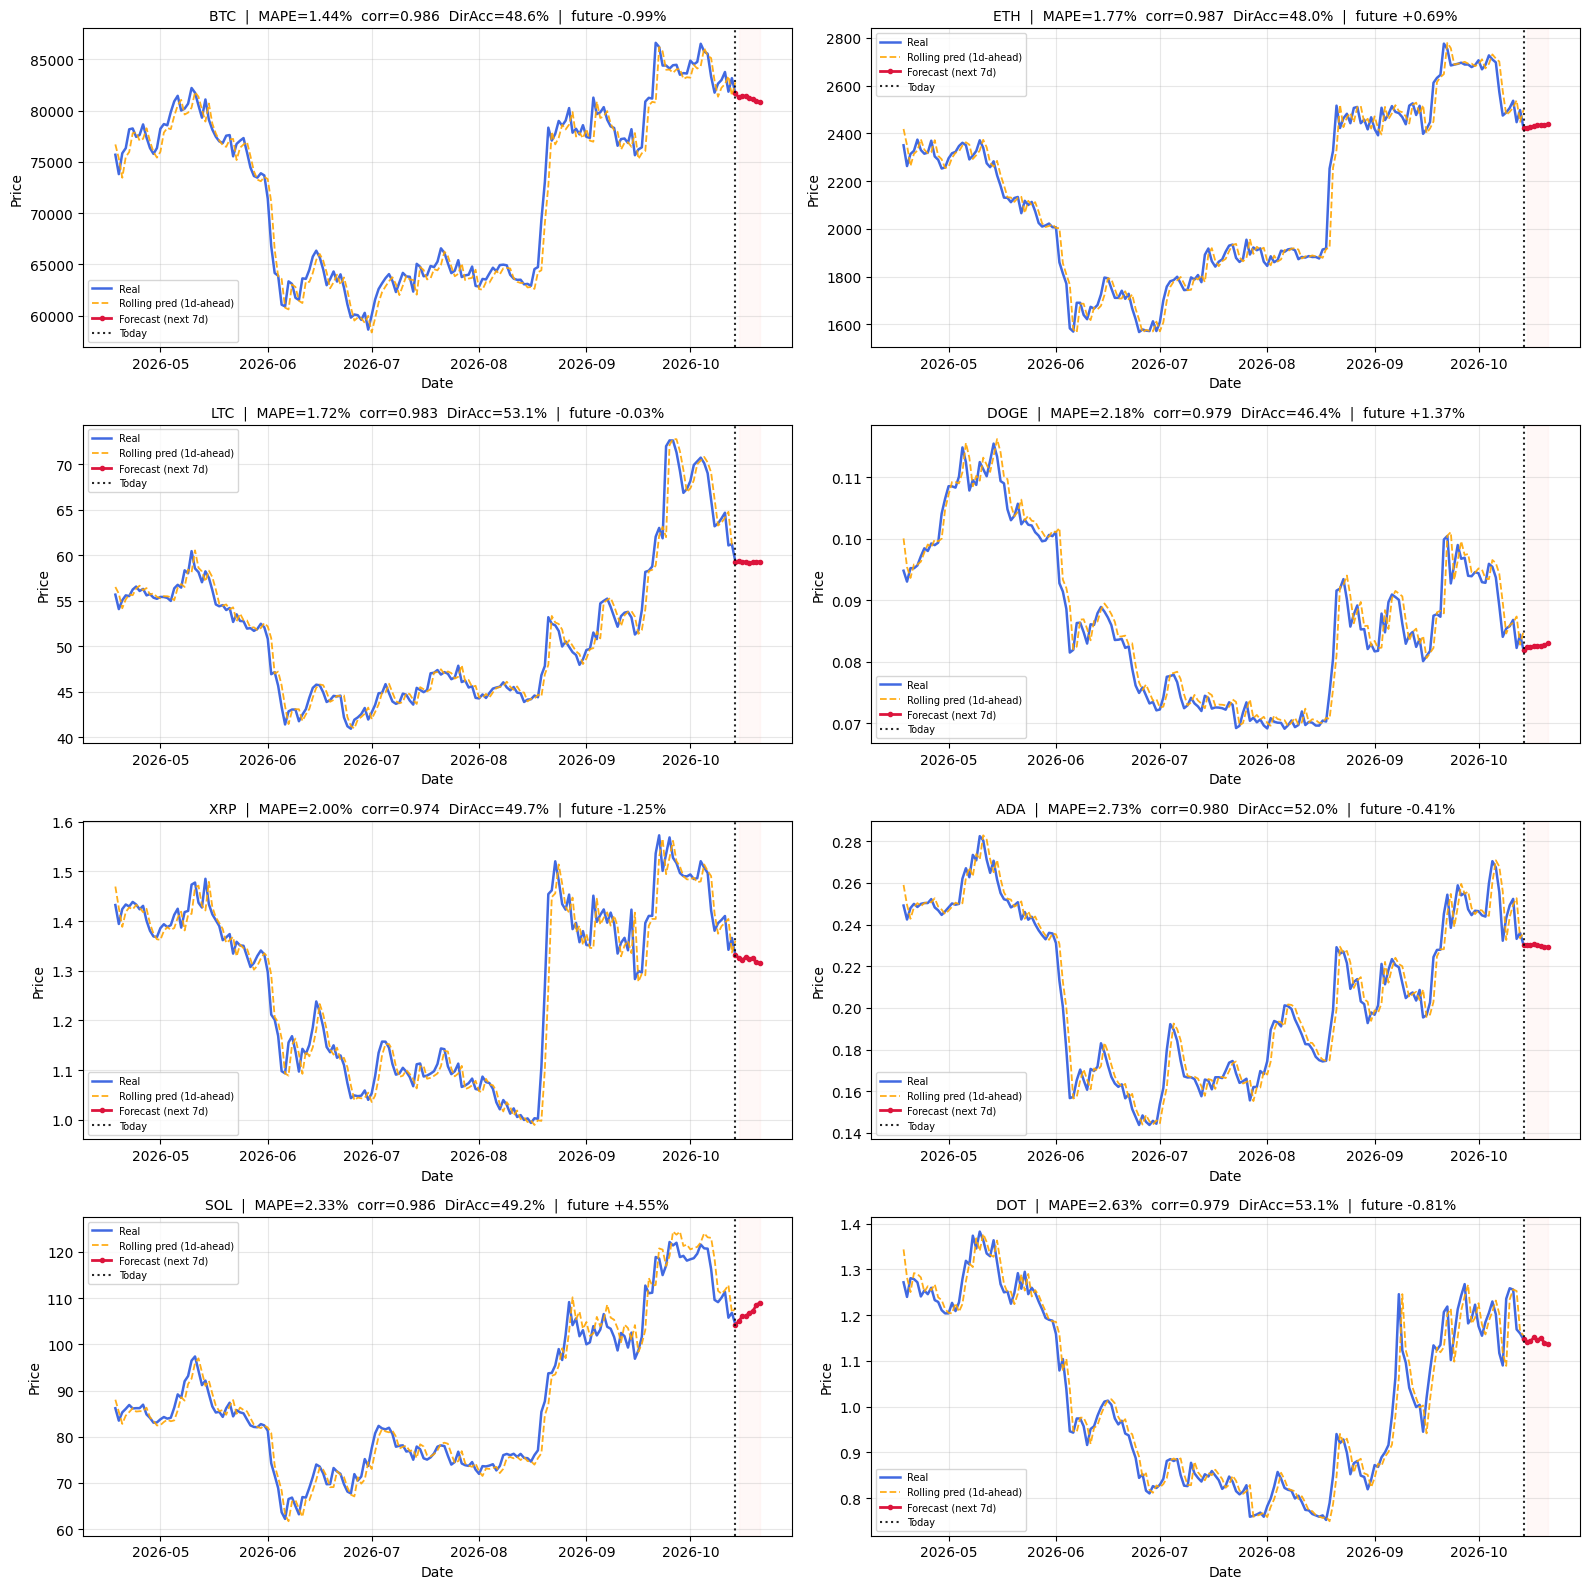


PAST / PRESENT / FUTURE SUMMARY  |  180d rolling  |  7d forecast
Coin   MAE ($)  MAPE %  Corr  DirAcc %  Last Price  D+7 Price  Forecast Return %
 BTC 1044.0514    1.44 0.986     48.60  81682.0100 80873.3359              -0.99
 ETH   37.4216    1.77 0.987     48.04   2421.6000  2438.2429               0.69
 LTC    0.9072    1.72 0.983     53.07     59.2800    59.2619              -0.03
DOGE    0.0019    2.18 0.979     46.37      0.0819     0.0830               1.37
 XRP    0.0258    2.00 0.974     49.72      1.3316     1.3149              -1.25
 ADA    0.0056    2.73 0.980     51.96      0.2302     0.2293              -0.41
 SOL    2.0840    2.33 0.986     49.16    104.2900   109.0388               4.55
 DOT    0.0275    2.63 0.979     53.07      1.1470     1.1377              -0.81
Avg MAPE: 2.10%  |  Avg Corr: 0.982  |  Avg DirAcc: 50.00%


In [ ]:
# Cell 11 — Past, Present, and Future
def rolling_predict(symbol: str, n_days: int = 180):
    d = per_coin[symbol]
    close_values = d["df"]["close"].to_numpy()
    date_values = d["df"]["date"].to_numpy()
    n_rows = len(close_values)
    scaled = d["scaler"].transform(d["df"][feature_cols])

    windows, base_prices, target_indices = [], [], []
    for target_day in range(n_rows - n_days, n_rows):
        window_start = target_day - cfg.window_size
        if window_start < 0:
            continue
        windows.append(scaled[window_start:target_day])
        base_prices.append(close_values[target_day - 1])
        target_indices.append(target_day)

    windows = np.array(windows, dtype=np.float32)
    base_prices = np.array(base_prices, dtype=np.float32)
    target_indices = np.array(target_indices)

    pred_logret = predict_from_windows(symbol, windows)
    pred_first_day = base_prices * np.exp(pred_logret[:, 0])
    actual = close_values[target_indices]
    dates = pd.to_datetime(date_values[target_indices])
    return dates, actual, pred_first_day


def plot_past_present_future(n_days: int, future_days: int | None, save_path: Path) -> pd.DataFrame:
    future_days = cfg.forecast_horizon if future_days is None else future_days
    symbols = list(per_coin.keys())
    cols = 2
    rows = (len(symbols) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4.0 * rows))
    axes = axes.flatten()
    summary_rows = []

    for i, symbol in enumerate(symbols):
        dates, actual, pred = rolling_predict(symbol, n_days)

        mae = np.mean(np.abs(actual - pred))
        mape = np.mean(np.abs((actual - pred) / np.maximum(actual, 1e-9))) * 100
        corr = np.corrcoef(actual, pred)[0, 1] if np.std(actual) > 1e-8 and np.std(pred) > 1e-8 else np.nan
        dir_acc = np.mean(np.sign(np.diff(actual)) == np.sign(np.diff(pred))) * 100

        last_date = dates[-1]
        last_price = float(actual[-1])
        pred_future = predict_next(symbol)
        dates_future = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=future_days, freq="D")
        future_dates_plot = np.r_[np.datetime64(last_date), dates_future.values]
        future_prices_plot = np.r_[last_price, pred_future]
        expected_return = (pred_future[-1] / last_price - 1) * 100

        ax = axes[i]
        ax.plot(dates, actual, color="royalblue", linewidth=1.8, label="Real")
        ax.plot(dates, pred, color="orange", linewidth=1.3, linestyle="--", alpha=0.9, label="Rolling pred (1d-ahead)")
        ax.plot(future_dates_plot, future_prices_plot, color="crimson", linewidth=2.0, marker="o",
               markersize=3, label=f"Forecast (next {future_days}d)")
        ax.axvline(x=last_date, color="black", linestyle=":", linewidth=1.5, alpha=0.85, label="Today")
        ax.axvspan(dates_future[0], dates_future[-1], color="mistyrose", alpha=0.25)
        ax.set_title(f"{symbol}  |  MAPE={mape:.2f}%  corr={corr:.3f}  DirAcc={dir_acc:.1f}%  |  future {expected_return:+.2f}%",
                    fontsize=10)
        ax.set_xlabel("Date")
        ax.set_ylabel("Price")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7, loc="best")

        summary_rows.append({
            "Coin": symbol, "MAE ($)": round(mae, 4), "MAPE %": round(mape, 2),
            "Corr": round(corr, 3), "DirAcc %": round(dir_acc, 2),
            "Last Price": round(last_price, 4), f"D+{future_days} Price": round(float(pred_future[-1]), 4),
            "Forecast Return %": round(expected_return, 2),
        })

    for j in range(len(symbols), len(axes)):
        axes[j].axis("off")
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.show()
    return pd.DataFrame(summary_rows)


ppf_df = plot_past_present_future(n_days=180, future_days=None, save_path=cfg.figures_dir / "past_present_future.png")
print("\n" + "=" * 100)
print(f"PAST / PRESENT / FUTURE SUMMARY  |  180d rolling  |  {cfg.forecast_horizon}d forecast")
print("=" * 100)
print(ppf_df.to_string(index=False))
print("=" * 100)
print(f"Avg MAPE: {ppf_df['MAPE %'].mean():.2f}%  |  Avg Corr: {ppf_df['Corr'].mean():.3f}  |  "
     f"Avg DirAcc: {ppf_df['DirAcc %'].mean():.2f}%")

## 12. Saving Results

All tables and plots made above are saved into a `results/` folder, which is also what the README shows.

In [ ]:
# Cell 12 — Saving Results
report_df.to_csv(cfg.results_dir / "test_report.csv", index=False)
ppf_df.to_csv(cfg.results_dir / "past_present_future.csv", index=False)
print("Saved:", sorted(p.name for p in cfg.results_dir.iterdir() if p.is_file()))
print("Figures:", sorted(p.name for p in cfg.figures_dir.iterdir()))

Saved: ['past_present_future.csv', 'test_report.csv']
Figures: ['past_present_future.png', 'training_curves.png']


## 13. Conclusion

**Result of this run:** 3 of 8 coins (LTC, DOGE, XRP) beat the simple "price stays the same" baseline on
the test set. Directional accuracy averaged 50.7% on the test set and 49.8% on the 180-day rolling check —
both close to 50%, which is random guessing. The high correlation values (0.97-0.99) mostly come from both
the real and predicted lines drifting with the same overall price trend, not from the model calling
short-term direction correctly.

One coin is worth flagging on its own: SOL's live forecast shows the largest predicted move of any coin
(+5.89% over 7 days), while SOL also had the worst directional accuracy (45.8%) and worst MAPE (6.04%) of
the eight coins on the test set. The model is most confident exactly where it has been least reliable —
treat that forecast with extra caution rather than extra confidence.

**Bottom line:** this model is not yet reliable for predicting direction. It tracks the recent price trend
more than it forecasts what happens next, which is normal for price-based deep learning models on noisy,
largely unpredictable short-horizon crypto returns.

**Reading the numbers correctly:** the `loss`/`mae` in Section 7 are on returns, not price — a good-looking
`val_loss` does not by itself mean the price forecast is accurate. Always check the `Beats Naive?` and
`Dir Acc %` columns in Sections 10 and 11 to judge whether the model is really adding value.

**Known limits:**
- The raw `close` price feature can still go outside its trained range during a strong trend.
- Only daily price and volume data is used — no news, sentiment, or on-chain data.
- The train/test split covers one period in time; results may differ in calmer or wilder markets.
- Price is much harder to predict than volatility — treat directional accuracy with real caution before
  acting on it.
